## Random Forest vs a Single Decision Tree:

A single decision tree that is grown to full depth memorises its training data, including the noise in it. That makes it a **high-variance** model.
A random forest trains many trees on different random samples of the data and **averages** them, which cancels out much of that noise.

This notebook shows the effect visually on two toy problems:

1. **Classification:** two noisy concentric circles, where we can see the decision boundaries
2. **Regression:** a noisy curve, where we can see the fitted function

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from sklearn.datasets import make_circles
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

RANDOM_STATE = 42

## 1. Classification: Concentric Circles:

The two classes form noisy circles around the same centre. With `noise=0.35` they overlap a lot, so no model can be perfect here.
The interesting question is which model gets closest *without* memorising the noise.

X: (500, 2)   class counts: [250 250]


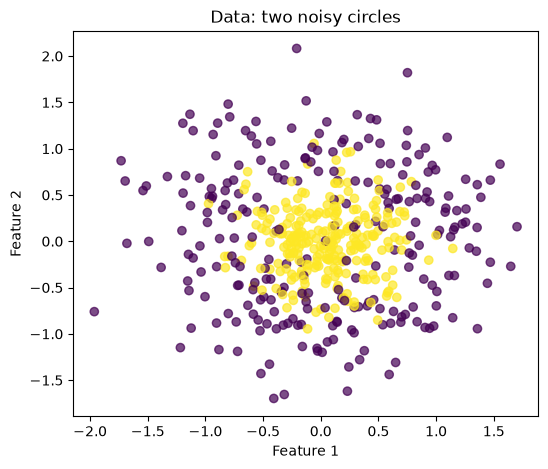

In [2]:
X, y = make_circles(n_samples=500, factor=0.1, noise=0.35, random_state=RANDOM_STATE)
print(f"X: {X.shape}   class counts: {np.bincount(y)}")

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", alpha=0.7)
plt.title("Data: two noisy circles")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"train: {X_train.shape}   test: {X_test.shape}")

train: (400, 2)   test: (100, 2)


### Fit both models:

In [4]:
tree_clf = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
forest_clf = RandomForestClassifier(
    n_estimators=500,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE
).fit(X_train, y_train)

In [5]:
for name, model in [("Decision tree", tree_clf), ("Random forest", forest_clf)]:
    print(f"{name}: train accuracy = {model.score(X_train, y_train):.3f} | test accuracy = {model.score(X_test, y_test):.3f}")
    
print(f"Random forest OOB accuracy: {forest_clf.oob_score_:.3f}")

Decision tree: train accuracy = 1.000 | test accuracy = 0.720
Random forest: train accuracy = 1.000 | test accuracy = 0.810
Random forest OOB accuracy: 0.812


A large gap between train and test accuracy means overfitting. A fully grown tree reaches (close to) 100% on the training data, but it falls back on the test data.

### Decision boundaries:

In [6]:
def plot_decision_boundary(ax, model, title, pad=0.5, resolution=200):
    x1 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, resolution)
    x2 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, resolution)
    xx1, xx2 = np.meshgrid(x1, x2)
    zz = model.predict(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

    ax.contourf(xx1, xx2, zz, levels=[-0.5, 0.5, 1.5], cmap="viridis", alpha=0.2)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="viridis", alpha=0.6, s=25)
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="viridis", marker="^", edgecolor="k", linewidth=0.6, s=45)
    ax.set_title(f"{title}\n(test accuracy = {model.score(X_test, y_test):.3f})")
    ax.set_xlabel("Feature 1")

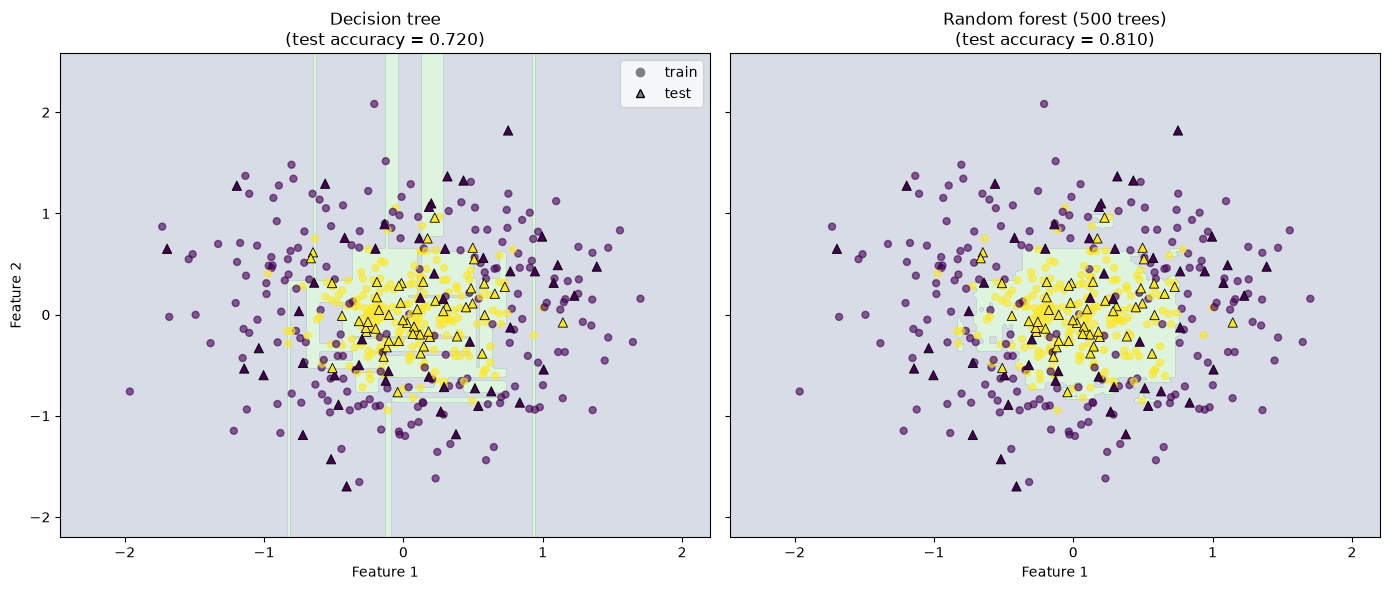

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
plot_decision_boundary(axes[0], tree_clf, "Decision tree")
plot_decision_boundary(axes[1], forest_clf, "Random forest (500 trees)")
axes[0].set_ylabel("Feature 2")
axes[0].legend(
    handles=[
        Line2D([], [], marker="o", linestyle="", color="gray", label="train"),
        Line2D([], [], marker="^", linestyle="", color="gray", markeredgecolor="k", label="test"),
    ], loc="upper right",)

plt.tight_layout()
plt.show()

## 2. Regression: A Noisy Curve:

In [8]:
def f(x):
    x = np.ravel(x)
    return np.exp(-x ** 2) + 1.5 * np.exp(-(x - 2) ** 2)

def generate(n_samples, noise, rng):
    X = np.sort(rng.uniform(-5, 5, n_samples)).reshape(-1, 1)
    y = f(X) + rng.normal(0.0, noise, n_samples)
    return X, y

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
X_reg_train, y_reg_train = generate(n_samples=150, noise=0.1, rng=rng)
X_reg_test, y_reg_test = generate(n_samples=1000, noise=0.1, rng=rng)
print(f"train: {X_reg_train.shape}   test: {X_reg_test.shape}")

train: (150, 1)   test: (1000, 1)


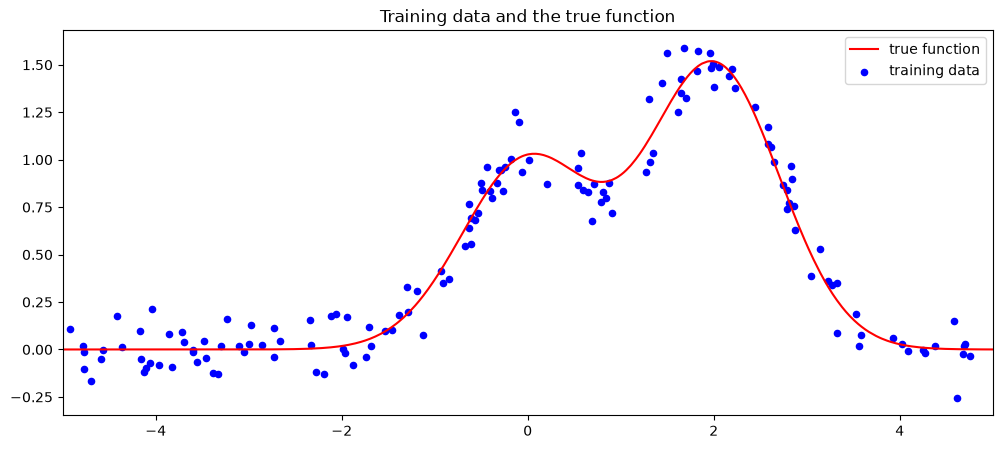

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(X_reg_test, f(X_reg_test), "r", label="true function")
plt.scatter(X_reg_train, y_reg_train, c="b", s=20, label="training data")
plt.xlim(-5, 5)
plt.title("Training data and the true function")
plt.legend()
plt.show()

### Fit both models:

In [11]:
tree_reg = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_reg_train, y_reg_train)
forest_reg = RandomForestRegressor(
    n_estimators=1000,
    n_jobs=-1,
    random_state=RANDOM_STATE
).fit(X_reg_train, y_reg_train)

In [12]:
for name, model in [("Decision tree", tree_reg), ("Random forest", forest_reg)]:
    pred = model.predict(X_reg_test)
    print(f"{name}: test MSE = {mean_squared_error(y_reg_test, pred):.4f} | test R2 = {r2_score(y_reg_test, pred):.3f}")

Decision tree: test MSE = 0.0209 | test R2 = 0.919
Random forest: test MSE = 0.0148 | test R2 = 0.943


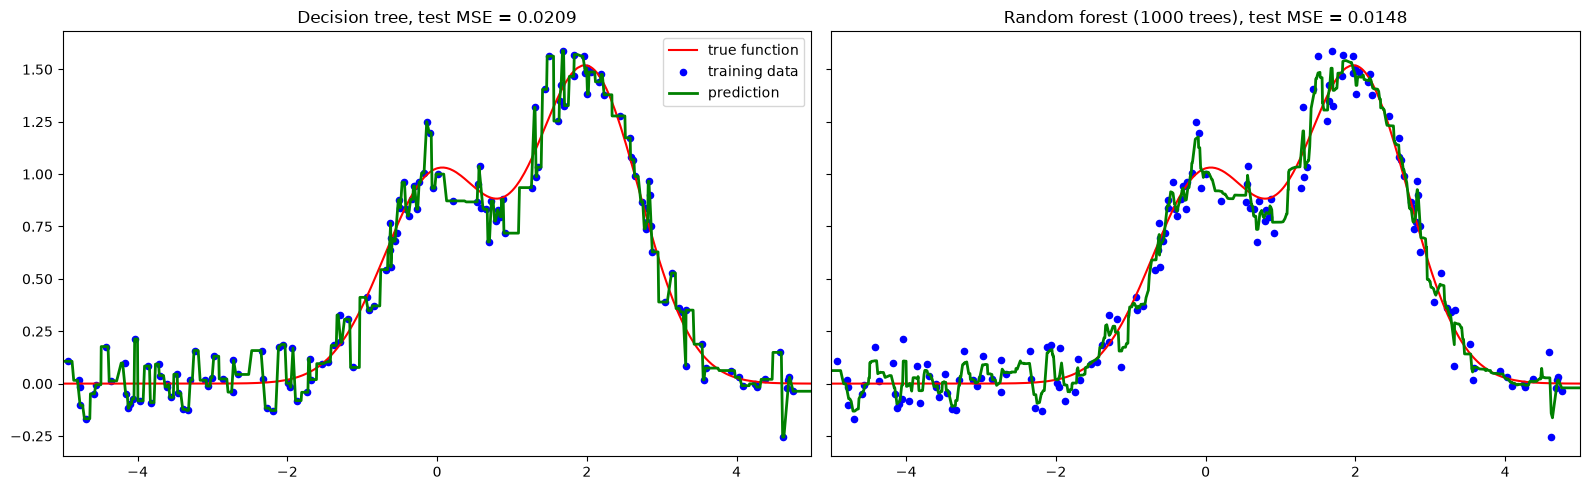

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, (title, model) in zip(axes, [("Decision tree", tree_reg), ("Random forest (1000 trees)", forest_reg)]):
    pred = model.predict(X_reg_test)
    ax.plot(X_reg_test, f(X_reg_test), "r", label="true function")
    ax.scatter(X_reg_train, y_reg_train, c="b", s=20, label="training data")
    ax.plot(X_reg_test, pred, "g", lw=2, label="prediction")
    ax.set_xlim(-5, 5)
    ax.set_title(f"{title}, test MSE = {mean_squared_error(y_reg_test, pred):.4f}")
axes[0].legend()
plt.tight_layout()
plt.show()

## 3. Takeaways:

- A fully grown decision tree has **low bias but high variance**: it fits the training noise, so its test score is much worse than its train score.
- A random forest keeps the low bias of deep trees but **averages away much of the variance**, so it generalises better.
- The gain comes from *decorrelated* trees: each one sees a bootstrap sample of the rows (and a random subset of features at each split).
- The out-of-bag score gives a validation estimate without holding out any data.